# Chuẩn bị MCF
- 24 scenario × 8 camera. Video AVI từ [Kaggle](https://www.kaggle.com/datasets/soumicksarker/multiple-cameras-fall-dataset).
- Khoảng nhãn và độ lệch camera lấy từ [báo cáo 2010](https://www-labs.iro.umontreal.ca/~labimage/Dataset/technicalReport.pdf) và [erratum 2025](https://www-labs.iro.umontreal.ca/~labimage/Dataset/Erratum-MCF.pdf).
- Lấy mẫu mỗi 4 frame trên mốc tham chiếu. Cả 8 góc ở cùng mốc đi chung tập và fold.
- Scenario 4 dùng thêm hiệu chỉnh +82 frame của đồ án.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image, ImageOps

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "papercode").is_dir())
paper = root / "papercode"
prepare = paper / "prepare-dataset"
postures = ["Đi/đứng", "Nằm", "Đang ngã", "Ngồi"]

In [2]:
assignment = pd.read_csv(prepare / "splits/mcf.csv")
samples = prepare / "dataraw/mcf/examples"
print(f"Số ảnh của benchmark: {len(assignment):,}")
display(pd.crosstab(assignment["posture"], assignment["split"]))
display(assignment[["sample_id", "split", "cv_fold"]].head())

Số ảnh của benchmark: 27,016


split,train,validation
posture,,
P1,14064,3520
P2,4328,1088
P3,1696,424
P4,1520,376


,sample_id,split,cv_fold
0,mcf_s01_c01_f000879,train,2
1,mcf_s01_c02_f000879,train,2
2,mcf_s01_c03_f000884,train,2
3,mcf_s01_c04_f000880,train,2
4,mcf_s01_c05_f000899,train,2


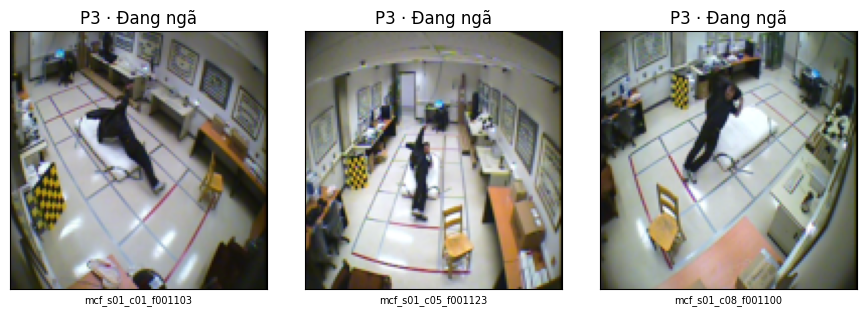

In [3]:
import matplotlib.pyplot as plt

photos = sorted((samples / "images").glob("mcf_s01_c*_f0011*.png"))[:3]
fig, axes = plt.subplots(1, len(photos), figsize=(9, 3))
for ax, photo in zip(np.atleast_1d(axes), photos):
    row = assignment.loc[assignment.sample_id.eq(photo.stem)].iloc[0]
    ax.imshow(Image.open(photo))
    ax.set_title(f"{row.posture} · {postures[row.label]}")
    ax.set_xlabel(photo.stem, fontsize=7)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

[Tải clip MCF mẫu](dataraw/mcf/examples/clip.mp4). Scenario 1, camera 8.

In [4]:
from IPython.display import Video
Video(str((samples / "clip.mp4").relative_to(Path.cwd())) if samples.is_relative_to(Path.cwd()) else str(samples / "clip.mp4"), width=480)

## Dựng lại từ file nguồn
- Đặt AVI theo cấu trúc Kaggle chuteXX/camY.avi trong dataraw/mcf.
- Đặt báo cáo với tên technical_report_2010.pdf. Các mốc erratum được ghi trong cell dưới.
- Bật PREPARE_RAW để lưu ảnh RGB 128×128 và manifest dưới prepared/mcf.

In [5]:
import re
from pypdf import PdfReader

CORRECTED_PERIODS = {
    2: [(308, 394), (395, 425), (426, 600)],
    7: [(330, 490), (491, 520), (521, 680)],
    8: [(144, 350), (351, 380), (381, 520)],
    14: [(372, 590), (591, 620), (621, 929), (930, 969), (970, 1019), (1020, 1060), (1061, 1115)],
    18: [(301, 480), (481, 520), (521, 655), (656, 684), (685, 710), (711, 740)],
}


PREPARE_RAW = False

def mcf_annotations(report):
    reader = PdfReader(report)
    offsets = {}
    for line in reader.pages[15].extract_text(extraction_mode="layout").splitlines():
        if not re.fullmatch(r"\s*\d+(?:\s+\d+){8,9}\s*", line):
            continue
        values = list(map(int, line.split()))
        if values[0] == 5 and len(values) == 10:
            values.pop(6)
        if len(values) == 9 and 1 <= values[0] <= 24:
            offsets[values[0]] = dict(enumerate(values[1:], 1))

    windows = {}
    scenario = None
    for page in reader.pages[16:22]:
        for line in page.extract_text(extraction_mode="layout").splitlines():
            if not re.fullmatch(r"\s*\d+(?:\s+\d+){2,4}\s*", line):
                continue
            values = list(map(int, line.split()))
            if len(values) == 5:
                scenario, camera, first, last, label = values
                camera = {11: 8, 10: 7}.get(camera, camera)
            elif len(values) == 3 and scenario is not None:
                first, last, label = values
            else:
                continue
            windows.setdefault(scenario, []).append((camera, first, last, label))
    for scenario, intervals in CORRECTED_PERIODS.items():
        windows[scenario] = [(camera, start, end, label) for
            (camera, _, _, label), (start, end) in zip(windows[scenario], intervals, strict=True)]
    return offsets, windows

def select_mcf_frames(delays, windows):
    labels = {1: 0, 3: 1, 2: 2, 7: 3}
    rows = []
    for scenario, segments in windows.items():
        offset = 82 if scenario == 4 else 0
        for reference, start, end, posture in segments:
            if posture not in labels:
                continue
            for t in range(start - 1 + offset, end + offset):
                if t % 4:
                    continue
                for camera, delay in delays[scenario].items():
                    frame = t + delay - delays[scenario][reference]
                    sample = f"mcf_s{scenario:02d}_c{camera:02d}_f{frame:06d}"
                    rows.append((sample, scenario, camera, frame, labels[posture]))
    return pd.DataFrame(rows, columns=["sample_id", "scenario", "camera", "frame_index", "label"])

def save_mcf_images(frames, raw, output):
    import cv2
    by_name = {p.parent.name.lower() + "/" + p.name.lower(): p for p in raw.rglob("*.avi")}
    (output / "images").mkdir(parents=True, exist_ok=True)
    for (scenario, camera), clip in frames.groupby(["scenario", "camera"]):
        key = f"chute{scenario:02d}/cam{camera}.avi"
        video = cv2.VideoCapture(str(by_name[key]))
        frame_index = -1
        try:
            for row in clip.sort_values("frame_index").itertuples(index=False):
                while frame_index < row.frame_index:
                    ok, image = video.read()
                    if not ok:
                        raise ValueError(f"Thiếu frame trong {key}: {row.frame_index}")
                    frame_index += 1
                rgb = Image.fromarray(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
                rgb.resize((128, 128), Image.Resampling.BILINEAR).save(output / "images" / f"{row.sample_id}.png")
        finally:
            video.release()

if PREPARE_RAW:
    raw = samples.parent
    output = prepare / "prepared/mcf"
    frames = select_mcf_frames(*mcf_annotations(raw / "technical_report_2010.pdf"))
    audit = assignment.merge(frames, on=["sample_id", "label"], how="outer", indicator=True, validate="one_to_one")
    if not audit["_merge"].eq("both").all():
        raise ValueError("Frame hoặc nhãn MCF khác split đã công bố")
    save_mcf_images(frames, raw, output)
    frames.assign(image_path="images/" + frames.sample_id + ".png").to_csv(output / "manifest.csv", index=False)

Cột cv_fold từ 0 đến 4 áp dụng cho tập train. Validation được giữ riêng với cv_fold = -1.